In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine Learning
from sklearn.linear_model import LogisticRegression

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve
)

# Save model
import joblib

# Warnings
import warnings
warnings.filterwarnings("ignore")

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
df = pd.read_csv("../Datasets/HR-Employee-Attrition.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [6]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [7]:
df.tail()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,...,3,80,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,...,1,80,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,...,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,...,4,80,0,17,3,2,9,6,0,8
1469,34,No,Travel_Rarely,628,Research & Development,8,3,Medical,1,2068,...,1,80,0,6,3,4,4,3,1,2


In [8]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 1470
Total Columns: 35


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


In [11]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (
        missing_values / len(df)
    ) * 100
})

missing_summary.sort_values(
    by="Missing Values",
    ascending=False
)

,Missing Values,Missing Percentage
Age,0,0.0
StandardHours,0,0.0
NumCompaniesWorked,0,0.0
Over18,0,0.0
OverTime,0,0.0
PercentSalaryHike,0,0.0
PerformanceRating,0,0.0
RelationshipSatisfaction,0,0.0
StockOptionLevel,0,0.0
MonthlyIncome,0,0.0


In [12]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [13]:
df.dtypes.value_counts()

int64     26
object     9
Name: count, dtype: int64

In [14]:
for column in df.columns:
    print(f"{column}: {df[column].nunique()} unique values")

Age: 43 unique values
Attrition: 2 unique values
BusinessTravel: 3 unique values
DailyRate: 886 unique values
Department: 3 unique values
DistanceFromHome: 29 unique values
Education: 5 unique values
EducationField: 6 unique values
EmployeeCount: 1 unique values
EmployeeNumber: 1470 unique values
EnvironmentSatisfaction: 4 unique values
Gender: 2 unique values
HourlyRate: 71 unique values
JobInvolvement: 4 unique values
JobLevel: 5 unique values
JobRole: 9 unique values
JobSatisfaction: 4 unique values
MaritalStatus: 3 unique values
MonthlyIncome: 1349 unique values
MonthlyRate: 1427 unique values
NumCompaniesWorked: 10 unique values
Over18: 1 unique values
OverTime: 2 unique values
PercentSalaryHike: 15 unique values
PerformanceRating: 2 unique values
RelationshipSatisfaction: 4 unique values
StandardHours: 1 unique values
StockOptionLevel: 4 unique values
TotalWorkingYears: 40 unique values
TrainingTimesLastYear: 7 unique values
WorkLifeBalance: 4 unique values
YearsAtCompany: 37 uni

In [15]:
eda_df = df.copy()

Attrition
No     1233
Yes     237
Name: count, dtype: int64


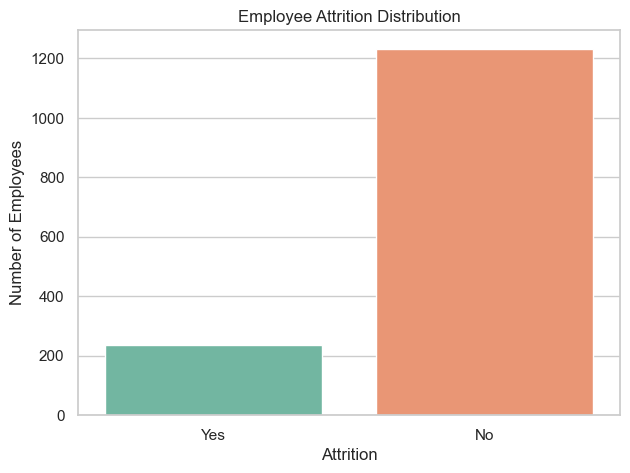

In [16]:
attrition_counts = eda_df["Attrition"].value_counts()

print(attrition_counts)

plt.figure(figsize=(7, 5))

sns.countplot(
    data=eda_df,
    x="Attrition",
    hue="Attrition",
    palette="Set2",
    legend=False
)

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")

plt.show()

Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


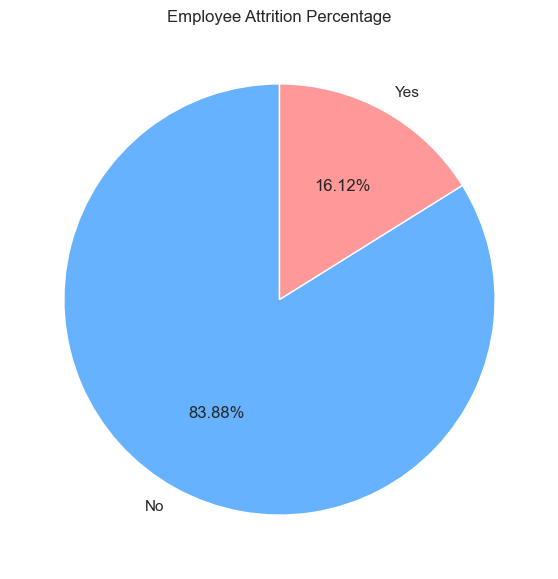

In [17]:
attrition_percentage = (
    eda_df["Attrition"]
    .value_counts(normalize=True) * 100
)

print(attrition_percentage)

plt.figure(figsize=(7, 7))

plt.pie(
    attrition_percentage,
    labels=attrition_percentage.index,
    autopct="%1.2f%%",
    startangle=90,
    colors=["#66B2FF", "#FF9999"]
)

plt.title("Employee Attrition Percentage")
plt.show()

Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


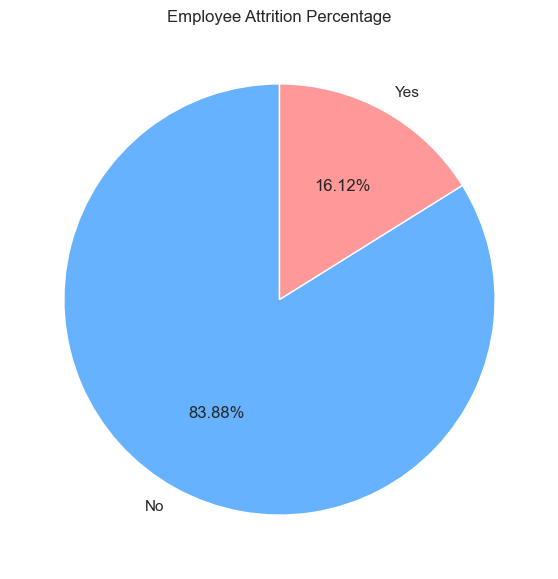

In [18]:
attrition_percentage = (
    eda_df["Attrition"]
    .value_counts(normalize=True) * 100
)

print(attrition_percentage)

plt.figure(figsize=(7, 7))

plt.pie(
    attrition_percentage,
    labels=attrition_percentage.index,
    autopct="%1.2f%%",
    startangle=90,
    colors=["#66B2FF", "#FF9999"]
)

plt.title("Employee Attrition Percentage")
plt.show()

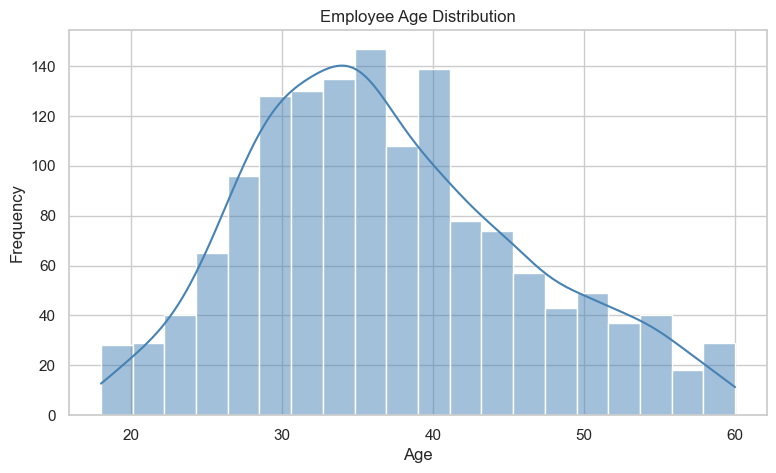

In [19]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=eda_df,
    x="Age",
    bins=20,
    kde=True,
    color="steelblue"
)

plt.title("Employee Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

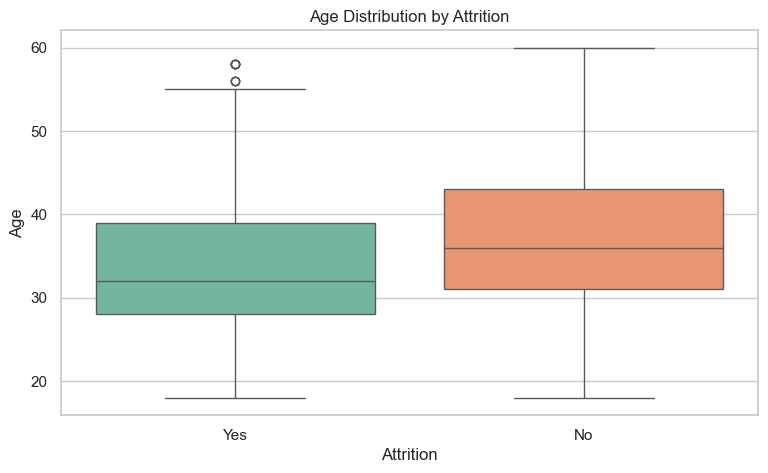

In [20]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=eda_df,
    x="Attrition",
    y="Age",
    hue="Attrition",
    palette="Set2",
    legend=False
)

plt.title("Age Distribution by Attrition")
plt.show()

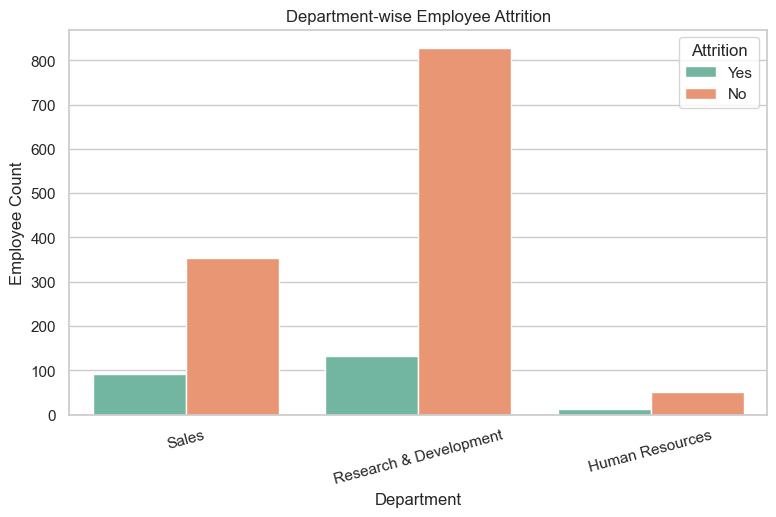

In [21]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=eda_df,
    x="Department",
    hue="Attrition",
    palette="Set2"
)

plt.title("Department-wise Employee Attrition")
plt.xlabel("Department")
plt.ylabel("Employee Count")

plt.xticks(rotation=15)
plt.legend(title="Attrition")

plt.show()

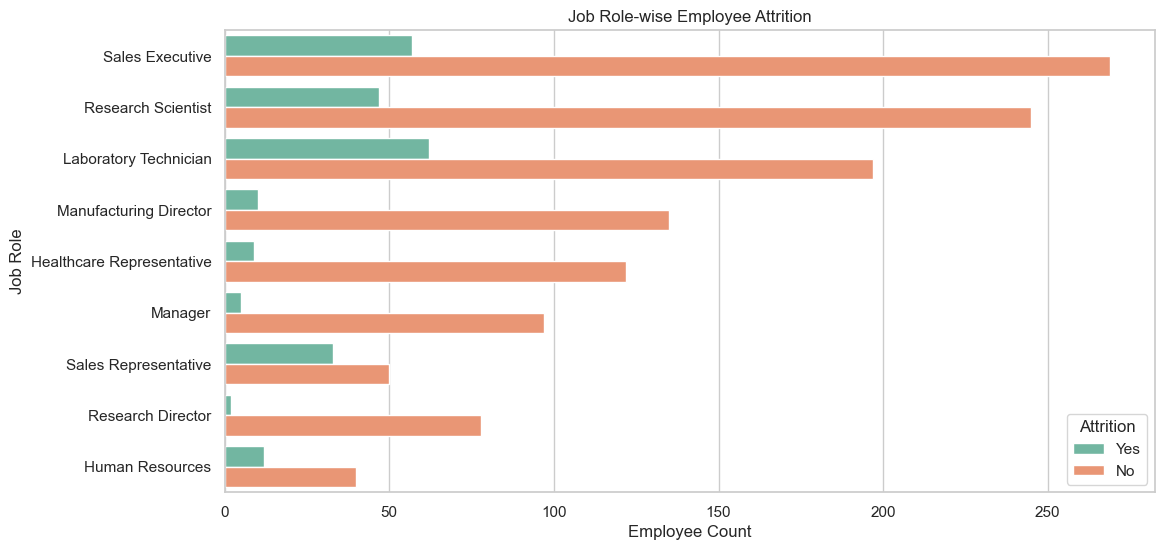

In [22]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=eda_df,
    y="JobRole",
    hue="Attrition",
    palette="Set2"
)

plt.title("Job Role-wise Employee Attrition")
plt.xlabel("Employee Count")
plt.ylabel("Job Role")

plt.show()

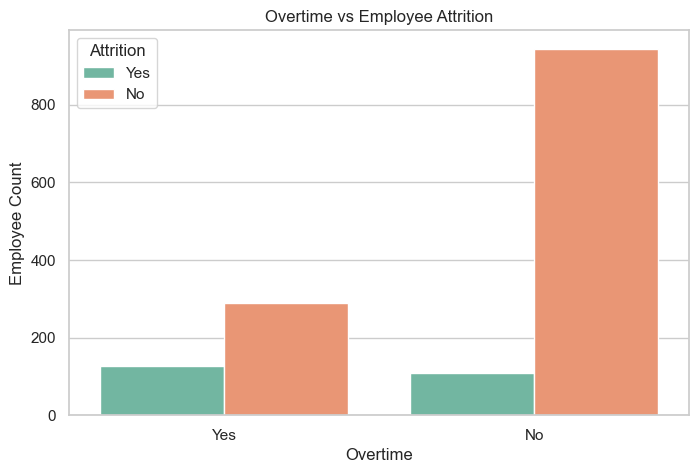

In [23]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=eda_df,
    x="OverTime",
    hue="Attrition",
    palette="Set2"
)

plt.title("Overtime vs Employee Attrition")
plt.xlabel("Overtime")
plt.ylabel("Employee Count")

plt.show()

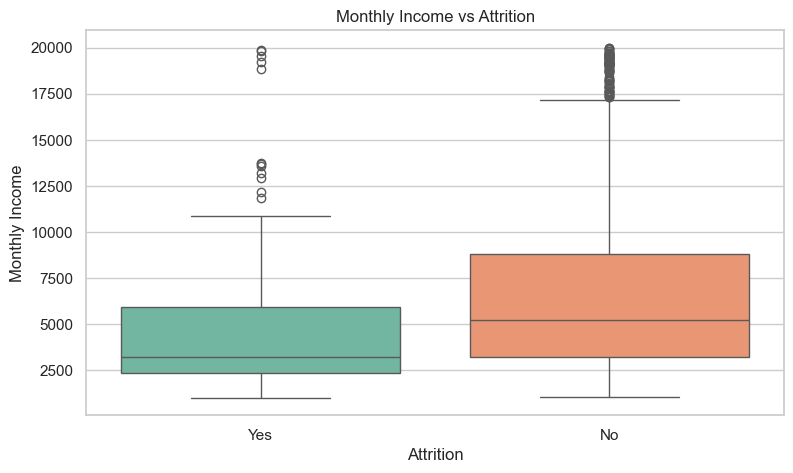

In [24]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=eda_df,
    x="Attrition",
    y="MonthlyIncome",
    hue="Attrition",
    palette="Set2",
    legend=False
)

plt.title("Monthly Income vs Attrition")
plt.xlabel("Attrition")
plt.ylabel("Monthly Income")

plt.show()

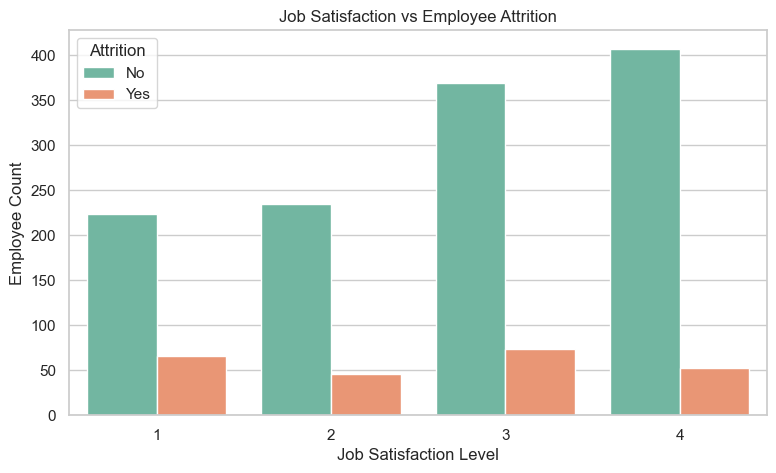

In [25]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=eda_df,
    x="JobSatisfaction",
    hue="Attrition",
    palette="Set2"
)

plt.title("Job Satisfaction vs Employee Attrition")
plt.xlabel("Job Satisfaction Level")
plt.ylabel("Employee Count")

plt.show()

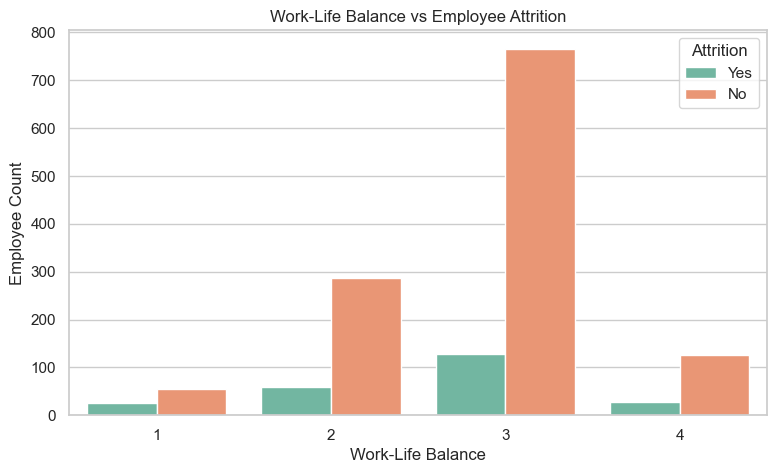

In [26]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=eda_df,
    x="WorkLifeBalance",
    hue="Attrition",
    palette="Set2"
)

plt.title("Work-Life Balance vs Employee Attrition")
plt.xlabel("Work-Life Balance")
plt.ylabel("Employee Count")

plt.show()

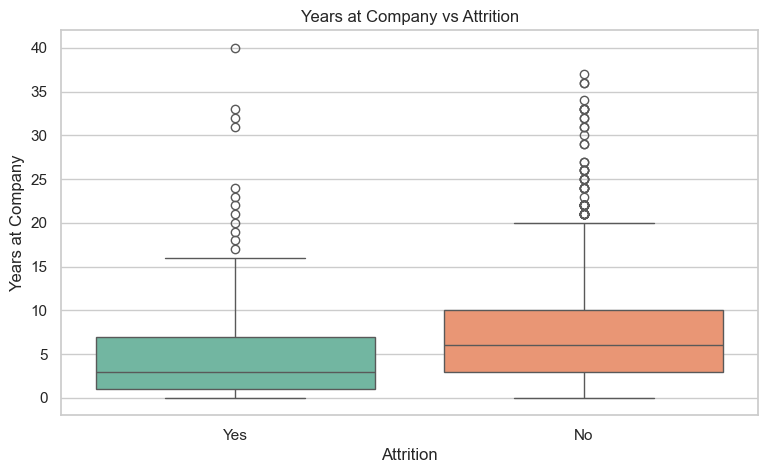

In [27]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=eda_df,
    x="Attrition",
    y="YearsAtCompany",
    hue="Attrition",
    palette="Set2",
    legend=False
)

plt.title("Years at Company vs Attrition")
plt.xlabel("Attrition")
plt.ylabel("Years at Company")

plt.show()

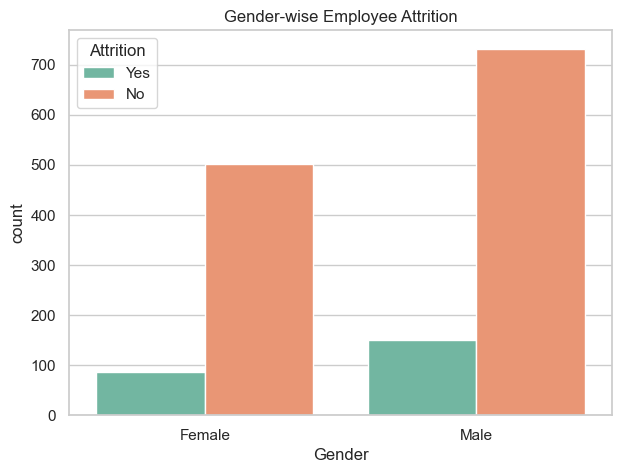

In [28]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=eda_df,
    x="Gender",
    hue="Attrition",
    palette="Set2"
)

plt.title("Gender-wise Employee Attrition")
plt.show()

In [29]:
numerical_summary = eda_df.describe().T

numerical_summary

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


In [30]:
categorical_summary = eda_df.describe(
    include="object"
).T

categorical_summary

,count,unique,top,freq
Attrition,1470,2,No,1233
BusinessTravel,1470,3,Travel_Rarely,1043
Department,1470,3,Research & Development,961
EducationField,1470,6,Life Sciences,606
Gender,1470,2,Male,882
JobRole,1470,9,Sales Executive,326
MaritalStatus,1470,3,Married,673
Over18,1470,1,Y,1470
OverTime,1470,2,No,1054


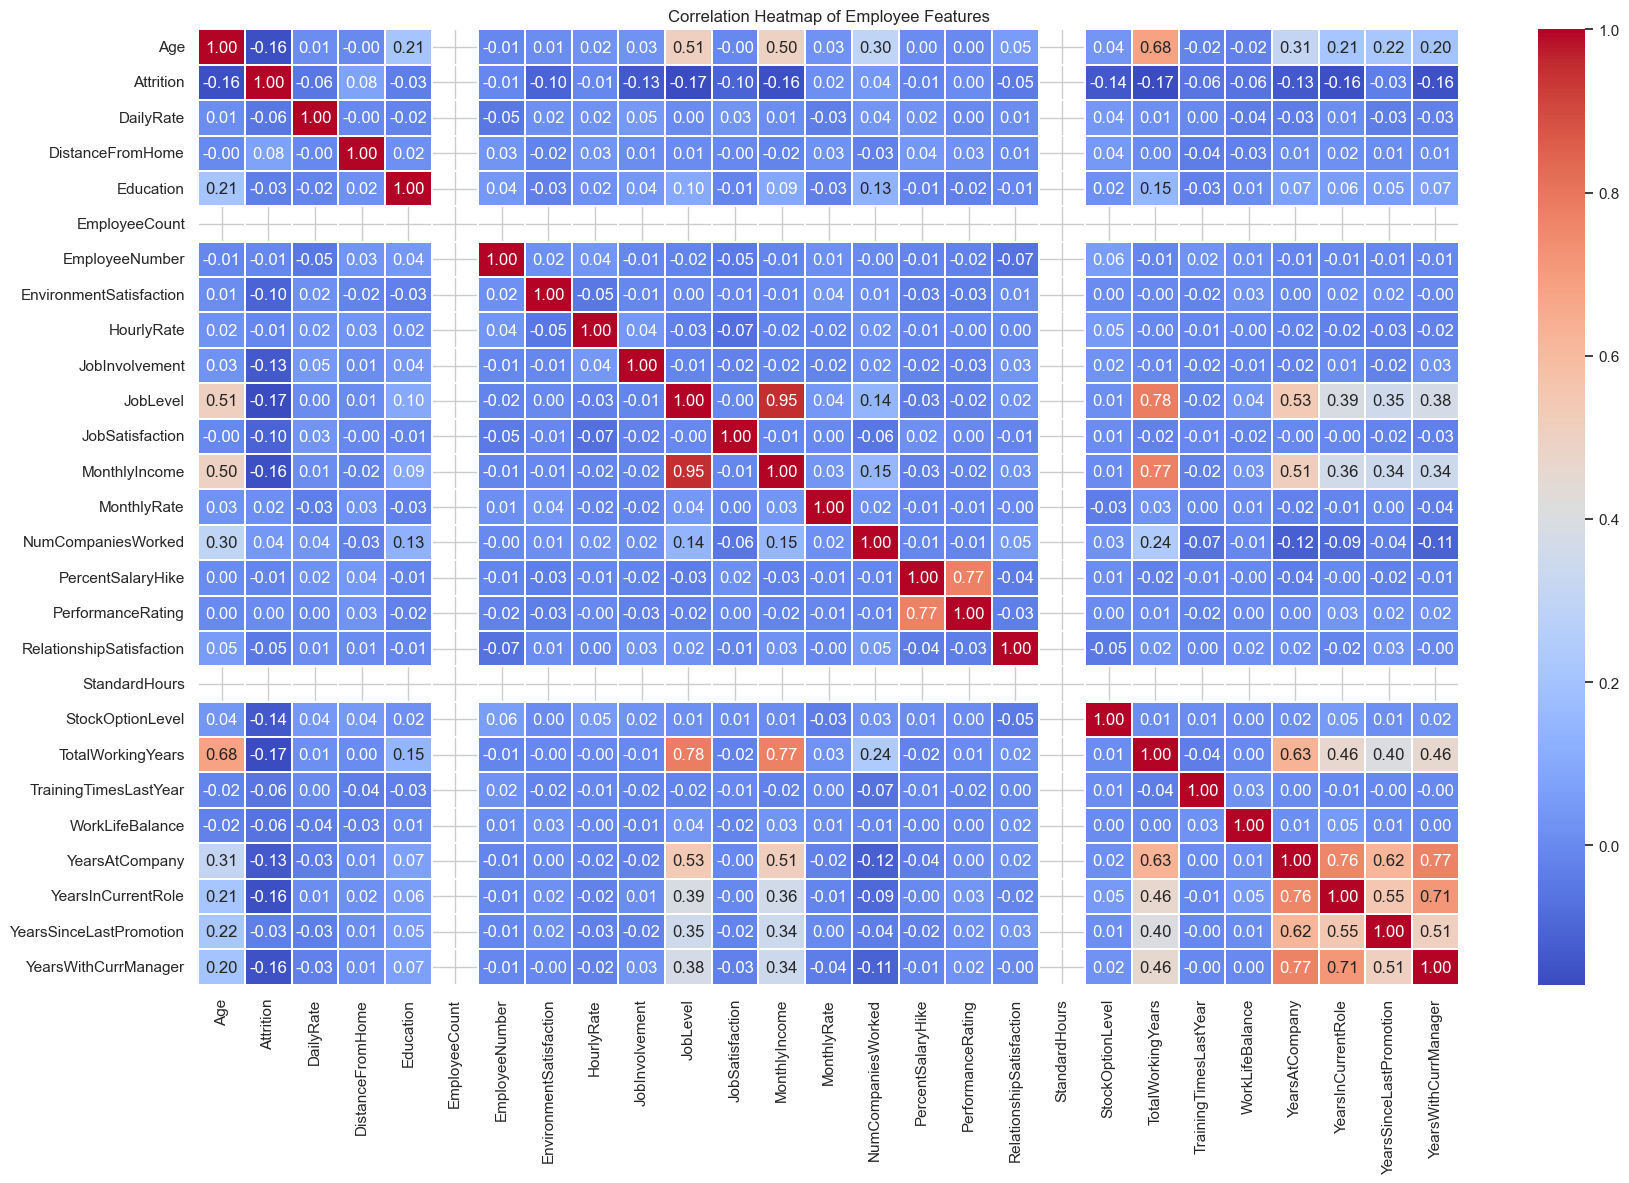

In [31]:
corr_df = eda_df.copy()

corr_df["Attrition"] = (
    corr_df["Attrition"].map({
        "No": 0,
        "Yes": 1
    })
)

numerical_corr = corr_df.select_dtypes(
    include=np.number
)

correlation_matrix = numerical_corr.corr()

plt.figure(figsize=(18, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    annot=True,
    fmt=".2f",
    linewidths=0.3
)

plt.title("Correlation Heatmap of Employee Features")
plt.tight_layout()
plt.show()

In [32]:
attrition_corr = (
    correlation_matrix["Attrition"]
    .drop("Attrition")
    .sort_values(key=abs, ascending=False)
)

print("Top Features Associated with Attrition:")

display(
    attrition_corr.to_frame(
        name="Correlation with Attrition"
    )
)

Top Features Associated with Attrition:


,Correlation with Attrition
TotalWorkingYears,-0.171063
JobLevel,-0.169105
YearsInCurrentRole,-0.160545
MonthlyIncome,-0.159840
Age,-0.159205
YearsWithCurrManager,-0.156199
StockOptionLevel,-0.137145
YearsAtCompany,-0.134392
JobInvolvement,-0.130016
JobSatisfaction,-0.103481


In [33]:
group_analysis = eda_df.groupby(
    "Attrition"
)[[
    "Age",
    "MonthlyIncome",
    "YearsAtCompany",
    "JobSatisfaction",
    "WorkLifeBalance",
    "DistanceFromHome"
]].mean().round(2)

group_analysis

,Age,MonthlyIncome,YearsAtCompany,JobSatisfaction,WorkLifeBalance,DistanceFromHome
Attrition,,,,,,
No,37.56,6832.74,7.37,2.78,2.78,8.92
Yes,33.61,4787.09,5.13,2.47,2.66,10.63


,Department,Attrition Rate (%)
0,Sales,20.627803
1,Human Resources,19.047619
2,Research & Development,13.839750


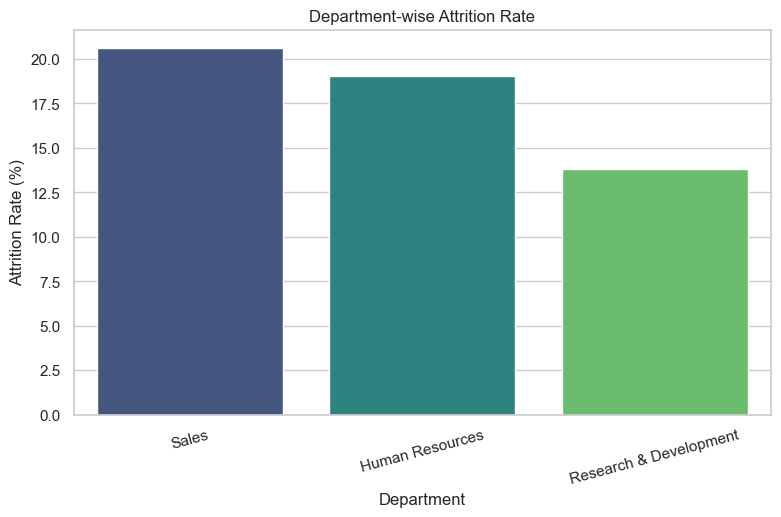

In [34]:
department_attrition = (
    eda_df.groupby("Department")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
    .reset_index(name="Attrition Rate (%)")
)

display(department_attrition)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=department_attrition,
    x="Department",
    y="Attrition Rate (%)",
    hue="Department",
    palette="viridis",
    legend=False
)

plt.title("Department-wise Attrition Rate")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=15)
plt.show()

In [35]:
model_df = df.copy()

# Encode target variable
model_df["Attrition"] = model_df["Attrition"].map({
    "No": 0,
    "Yes": 1
})

print(model_df.head())

   Age  Attrition     BusinessTravel  DailyRate              Department  \
0   41          1      Travel_Rarely       1102                   Sales   
1   49          0  Travel_Frequently        279  Research & Development   
2   37          1      Travel_Rarely       1373  Research & Development   
3   33          0  Travel_Frequently       1392  Research & Development   
4   27          0      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Medical              1               7   

   ...  RelationshipSatisfaction StandardHours  StockOptionLevel  \


In [36]:
print(model_df["Attrition"].value_counts())

print("\nUnique target values:")
print(model_df["Attrition"].unique())

print("\nAttrition percentage:")
print(
    model_df["Attrition"]
    .value_counts(normalize=True) * 100
)

Attrition
0    1233
1     237
Name: count, dtype: int64

Unique target values:
[1 0]

Attrition percentage:
Attrition
0    83.877551
1    16.122449
Name: proportion, dtype: float64


In [37]:
columns_to_drop = [
    "EmployeeNumber",
    "EmployeeCount",
    "Over18",
    "StandardHours"
]

model_df = model_df.drop(
    columns=columns_to_drop
)

print("Updated Dataset Shape:", model_df.shape)

Updated Dataset Shape: (1470, 31)


In [38]:
X = model_df.drop(
    columns=["Attrition"]
)

y = model_df["Attrition"]

print("Independent Features:", X.shape)
print("Dependent Target:", y.shape)

Independent Features: (1470, 30)
Dependent Target: (1470,)


In [39]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:", len(numerical_features))
print("Categorical Features:", len(categorical_features))

print("\nNumerical Columns:")
print(numerical_features)

print("\nCategorical Columns:")
print(categorical_features)

Numerical Features: 23
Categorical Features: 7

Numerical Columns:
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Categorical Columns:
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


In [40]:
class_distribution = pd.DataFrame({
    "Employee Count": y.value_counts(),
    "Percentage": y.value_counts(normalize=True) * 100
})

class_distribution.index = [
    "Stayed" if i == 0 else "Left"
    for i in class_distribution.index
]

display(class_distribution)

,Employee Count,Percentage
Stayed,1233,83.877551
Left,237,16.122449


In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=10,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Data: (1176, 30)
Testing Data: (294, 30)

Training Target Distribution:
Attrition
0    986
1    190
Name: count, dtype: int64

Testing Target Distribution:
Attrition
0    247
1     47
Name: count, dtype: int64


In [42]:
numerical_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

In [43]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_transformer,
            numerical_features
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [44]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=10
            )
        )
    ]
)

print(logistic_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical', StandardScaler(),
                                                  ['Age', 'DailyRate',
                                                   'DistanceFromHome',
                                                   'Education',
                                                   'EnvironmentSatisfaction',
                                                   'HourlyRate',
                                                   'JobInvolvement', 'JobLevel',
                                                   'JobSatisfaction',
                                                   'MonthlyIncome',
                                                   'MonthlyRate',
                                                   'NumCompaniesWorked',
                                                   'PercentSalaryHike',
                                                   'PerformanceRating',
                                   

In [45]:
logistic_model.fit(
    X_train,
    y_train
)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [46]:
y_pred = logistic_model.predict(X_test)

y_probability = logistic_model.predict_proba(
    X_test
)[:, 1]

print("Predictions generated successfully!")

print("First 10 Predictions:")
print(y_pred[:10])

Predictions generated successfully!
First 10 Predictions:
[0 0 0 0 0 0 0 0 0 0]


In [47]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_probability
)

print("LOGISTIC REGRESSION PERFORMANCE")
print("=" * 40)

print(f"Accuracy:  {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print(f"F1 Score:  {f1 * 100:.2f}%")
print(f"ROC-AUC:   {roc_auc:.4f}")

LOGISTIC REGRESSION PERFORMANCE
Accuracy:  88.78%
Precision: 76.92%
Recall:    42.55%
F1 Score:  54.79%
ROC-AUC:   0.8296


In [48]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Stayed", "Left"],
        digits=4
    )
)

              precision    recall  f1-score   support

      Stayed     0.8993    0.9757    0.9359       247
        Left     0.7692    0.4255    0.5479        47

    accuracy                         0.8878       294
   macro avg     0.8342    0.7006    0.7419       294
weighted avg     0.8785    0.8878    0.8739       294



[[241   6]
 [ 27  20]]


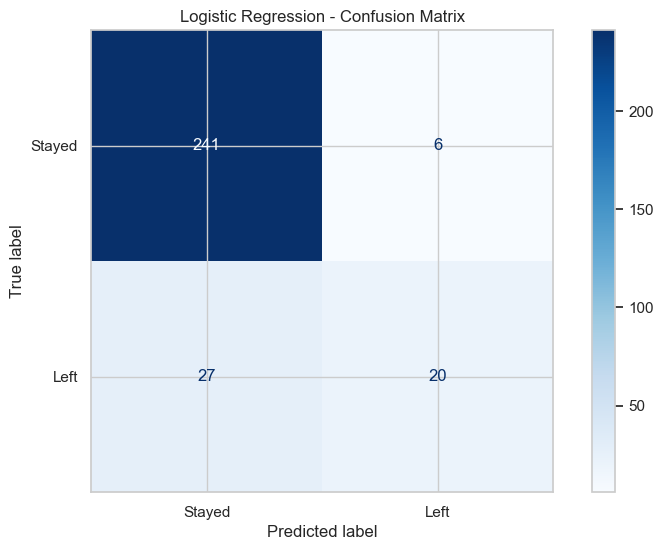

In [49]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Left"]
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

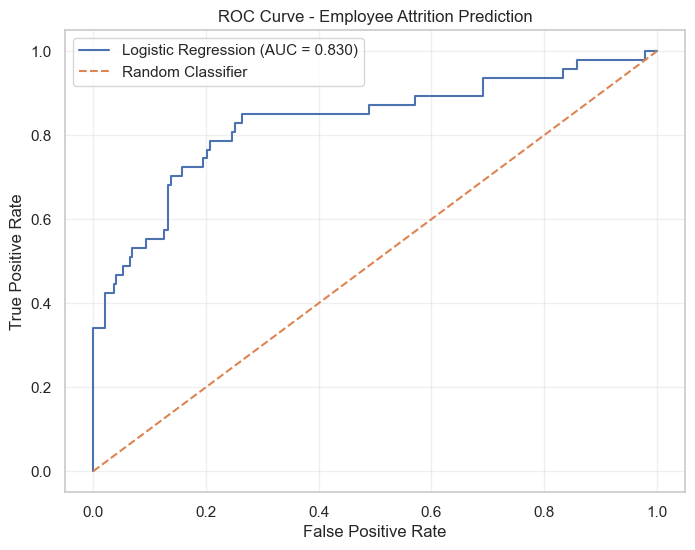

In [50]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probability
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Employee Attrition Prediction")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [51]:
comparison_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Attrition Probability": y_probability
})

comparison_df["Actual"] = comparison_df["Actual"].map({
    0: "Stayed",
    1: "Left"
})

comparison_df["Predicted"] = comparison_df["Predicted"].map({
    0: "Stayed",
    1: "Left"
})

comparison_df.head(15)

,Actual,Predicted,Attrition Probability
0,Stayed,Stayed,0.063555
1,Stayed,Stayed,0.097961
2,Stayed,Stayed,0.497876
3,Stayed,Stayed,0.011858
4,Stayed,Stayed,0.015725
5,Stayed,Stayed,0.338670
6,Stayed,Stayed,0.136619
7,Stayed,Stayed,0.077452
8,Stayed,Stayed,0.057930
9,Stayed,Stayed,0.071445


In [52]:
balanced_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=10
            )
        )
    ]
)

balanced_model.fit(
    X_train,
    y_train
)

print("Balanced Logistic Regression Trained Successfully!")

Balanced Logistic Regression Trained Successfully!


In [53]:
balanced_pred = balanced_model.predict(X_test)

balanced_probability = balanced_model.predict_proba(
    X_test
)[:, 1]

print("Balanced Predictions Generated!")

Balanced Predictions Generated!


In [54]:
print("BALANCED LOGISTIC REGRESSION")
print("=" * 40)

print(
    classification_report(
        y_test,
        balanced_pred,
        target_names=["Stayed", "Left"],
        digits=4
    )
)

print("Accuracy:",
      accuracy_score(y_test, balanced_pred))

print("Precision:",
      precision_score(y_test, balanced_pred))

print("Recall:",
      recall_score(y_test, balanced_pred))

print("F1 Score:",
      f1_score(y_test, balanced_pred))

print("ROC-AUC:",
      roc_auc_score(y_test, balanced_probability))

BALANCED LOGISTIC REGRESSION
              precision    recall  f1-score   support

      Stayed     0.9336    0.7976    0.8603       247
        Left     0.3976    0.7021    0.5077        47

    accuracy                         0.7823       294
   macro avg     0.6656    0.7498    0.6840       294
weighted avg     0.8480    0.7823    0.8039       294

Accuracy: 0.782312925170068
Precision: 0.39759036144578314
Recall: 0.7021276595744681
F1 Score: 0.5076923076923077
ROC-AUC: 0.8240158497717288


In [55]:
model_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],

    "Logistic Regression": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_probability)
    ],

    "Balanced Logistic Regression": [
        accuracy_score(y_test, balanced_pred),
        precision_score(y_test, balanced_pred),
        recall_score(y_test, balanced_pred),
        f1_score(y_test, balanced_pred),
        roc_auc_score(y_test, balanced_probability)
    ]
})

display(
    model_comparison.round(4)
)

,Metric,Logistic Regression,Balanced Logistic Regression
0,Accuracy,0.8878,0.7823
1,Precision,0.7692,0.3976
2,Recall,0.4255,0.7021
3,F1 Score,0.5479,0.5077
4,ROC-AUC,0.8296,0.8240


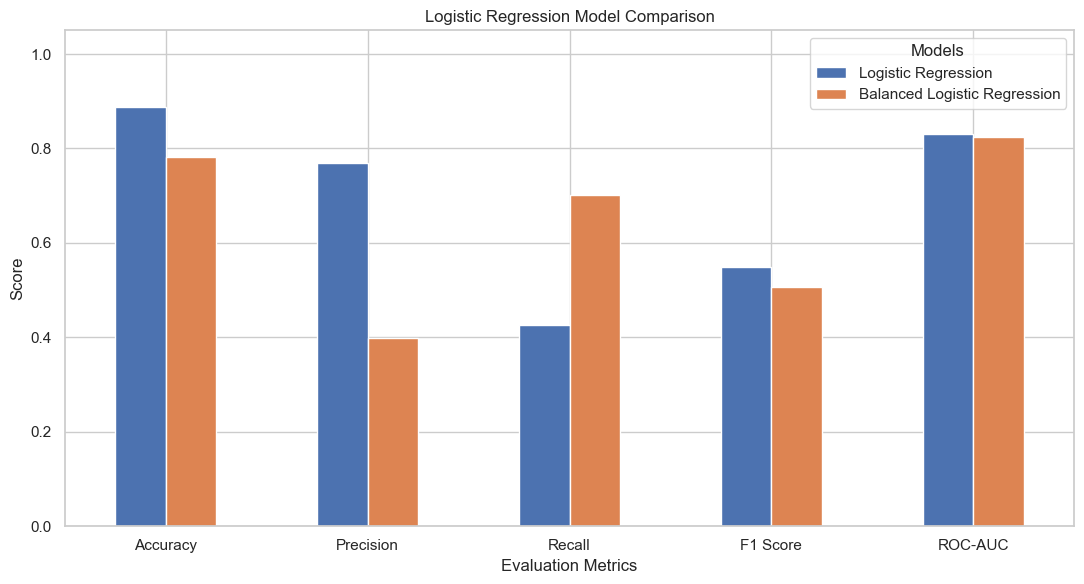

In [56]:
comparison_plot = model_comparison.set_index(
    "Metric"
)

comparison_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Logistic Regression Model Comparison")
plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.xticks(rotation=0)
plt.ylim(0, 1.05)
plt.legend(title="Models")

plt.tight_layout()
plt.show()

In [57]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=10
)

original_cv_scores = cross_val_score(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1"
)

balanced_cv_scores = cross_val_score(
    balanced_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1"
)

print("Original Model CV Scores:")
print(original_cv_scores)

print("\nBalanced Model CV Scores:")
print(balanced_cv_scores)

print("\nOriginal Mean F1:",
      original_cv_scores.mean())

print("Balanced Mean F1:",
      balanced_cv_scores.mean())

Original Model CV Scores:
[0.5483871  0.53731343 0.46153846 0.50847458 0.6440678 ]

Balanced Model CV Scores:
[0.50434783 0.44628099 0.48214286 0.56603774 0.56862745]

Original Mean F1: 0.5399562728059664
Balanced Mean F1: 0.5134873723589599


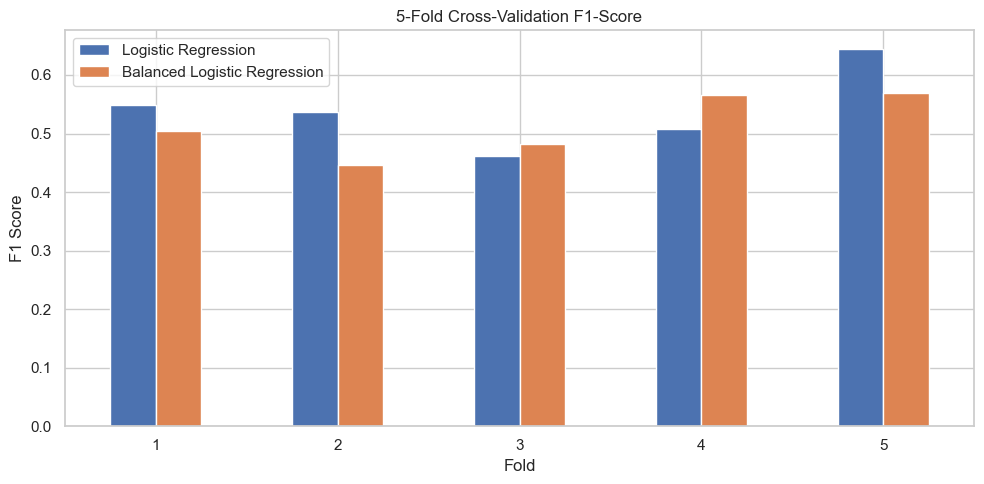

In [58]:
cv_results = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "Logistic Regression": original_cv_scores,
    "Balanced Logistic Regression": balanced_cv_scores
})

cv_results.set_index("Fold").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("5-Fold Cross-Validation F1-Score")
plt.ylabel("F1 Score")
plt.xlabel("Fold")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [59]:
fitted_preprocessor = logistic_model.named_steps[
    "preprocessor"
]

feature_names = fitted_preprocessor.get_feature_names_out()

coefficients = (
    logistic_model.named_steps["classifier"].coef_[0]
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

feature_importance["Absolute Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

feature_importance.head(15)

,Feature,Coefficient,Absolute Coefficient
49,categorical__OverTime_No,-1.017333,1.017333
50,categorical__OverTime_Yes,0.993956,0.993956
23,categorical__BusinessTravel_Non-Travel,-0.921776,0.921776
24,categorical__BusinessTravel_Travel_Frequently,0.857083,0.857083
45,categorical__JobRole_Sales Representative,0.745628,0.745628
42,categorical__JobRole_Research Director,-0.715160,0.715160
39,categorical__JobRole_Laboratory Technician,0.695862,0.695862
48,categorical__MaritalStatus_Single,0.643691,0.643691
21,numerical__YearsSinceLastPromotion,0.589248,0.589248
29,categorical__EducationField_Human Resources,0.587654,0.587654


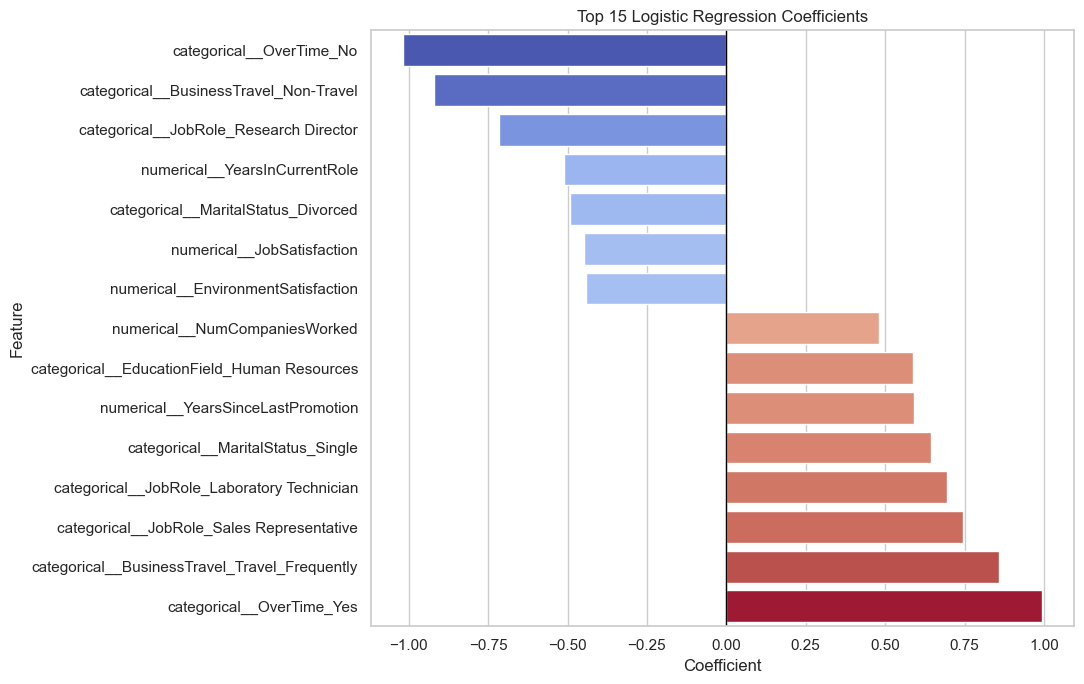

In [60]:
top_features = feature_importance.head(15).sort_values(
    by="Coefficient"
)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=top_features,
    x="Coefficient",
    y="Feature",
    hue="Coefficient",
    palette="coolwarm",
    legend=False
)

plt.axvline(
    0,
    color="black",
    linewidth=1
)

plt.title("Top 15 Logistic Regression Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [61]:
if balanced_cv_scores.mean() > original_cv_scores.mean():

    final_model = balanced_model
    final_model_name = "Balanced Logistic Regression"

else:

    final_model = logistic_model
    final_model_name = "Logistic Regression"

print("Selected Model:", final_model_name)

Selected Model: Logistic Regression


In [62]:
final_predictions = final_model.predict(X_test)

final_probabilities = final_model.predict_proba(
    X_test
)[:, 1]

final_accuracy = accuracy_score(
    y_test,
    final_predictions
)

final_precision = precision_score(
    y_test,
    final_predictions
)

final_recall = recall_score(
    y_test,
    final_predictions
)

final_f1 = f1_score(
    y_test,
    final_predictions
)

final_roc_auc = roc_auc_score(
    y_test,
    final_probabilities
)

final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],

    "Score": [
        final_accuracy,
        final_precision,
        final_recall,
        final_f1,
        final_roc_auc
    ]
})

display(final_results.round(4))

,Metric,Score
0,Accuracy,0.8878
1,Precision,0.7692
2,Recall,0.4255
3,F1 Score,0.5479
4,ROC-AUC,0.8296


In [63]:
joblib.dump(
    final_model,
    "employee_attrition_model.pkl"
)

print("Final model saved successfully!")

Final model saved successfully!


In [64]:
loaded_model = joblib.load(
    "employee_attrition_model.pkl"
)

sample_predictions = loaded_model.predict(
    X_test.head(5)
)

print("Model loaded successfully!")
print("Sample Predictions:", sample_predictions)

Model loaded successfully!
Sample Predictions: [0 0 0 0 0]


In [66]:
final_results.to_csv(
    "model_evaluation_results.csv",
    index=False
)

print("Evaluation report exported successfully!")

Evaluation report exported successfully!
